# Task result loader

This notebook opens an existing policy result store, dispatches to the policy-specific formatter, and inspects the returned `PolicyFormattedResults` payload. By default it selects the most recent `.zarr` store under `artifacts/`; override `result_store_path` below if you want a specific run.


In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import TwoSlopeNorm

project_root = Path.cwd()
if not (project_root / "tasks").exists():
    project_root = project_root.parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

try:
    import scienceplots  # noqa: F401
except ModuleNotFoundError:
    scienceplots = None
else:
    plt.style.use("science")
from network_creation.observers.social_welfare_observer import NormalizedWelfareObserver
from tasks.policies import load_policy_results
from network_creation.plotting.plot_pair import plot_pair
from matplotlib.ticker import FixedLocator
project_root


PosixPath('/home/hdahmou/Network_creation')

## Load and transform policy results


In [2]:
result_store_candidates = sorted(project_root.glob("artifacts/**/*.zarr"), key=lambda path: path.stat().st_mtime)
result_store_path = result_store_candidates[-1]

In [3]:
formatted = load_policy_results(result_store_path)
input_group = formatted.inputs
output_group = formatted.outputs
metadata = formatted.metadata
failure_arrays = formatted.failures
config = json.loads(Path(metadata["config_path"]).read_text(encoding="utf-8"))

{
    "result_store_path": str(metadata["result_store_path"]),
    "config_path": str(metadata["config_path"]),
    "task_name": metadata["task_name"],
    "task_class": metadata["task_class"],
    "output_schema": metadata["output_schema"],
    "input_tensors": {name: tensor.shape for name, tensor in input_group["tensors"].items()},
    "output_tensors": {name: tensor.shape for name, tensor in output_group["tensors"].items()},
}


{'result_store_path': '/home/hdahmou/Network_creation/artifacts/best_response_policy/best-response-policy-20260416T181542.zarr',
 'config_path': '/home/hdahmou/Network_creation/artifacts/best_response_policy/best-response-policy-20260416T181542.dispatch_config.json',
 'task_name': 'best-response-policy',
 'task_class': 'tasks.policies.best_response:BestResponsePolicyRun',
 'output_schema': [{'name': 'central_point_of_dominance.mean',
   'shape': [361],
   'dtype': 'float32'},
  {'name': 'normalized_welfare.mean', 'shape': [361], 'dtype': 'float32'}],
 'input_tensors': {'parameters': (16, 6)},
 'output_tensors': {'timeseries': (16, 2, 361), 'final': (16, 2)}}

In [4]:
{
    "input_dims": input_group["dims"],
    "output_dims": output_group["dims"],
    "input_label_sizes": {
        name: len(values) for name, values in input_group["labels"].items()
    },
    "output_label_sizes": {
        name: len(values) for name, values in output_group["labels"].items()
    },
}


{'input_dims': {'parameters': ('sample', 'parameter')},
 'output_dims': {'timeseries': ('sample', 'observable', 'step'),
  'final': ('sample', 'observable')},
 'input_label_sizes': {'sample': 16, 'parameter': 6},
 'output_label_sizes': {'sample': 16, 'observable': 2, 'step': 361}}

## Plot per-step outputs

This cell uses `outputs["tensors"]["timeseries"]` when the selected policy exposes a per-step tensor.


In [5]:
N = 10
rng = np.random.default_rng(42)

timeseries = output_group["tensors"]["timeseries"]  # shape: (num_samples, num_observables, num_steps)
n_total = timeseries.shape[0]
n_pick = min(N, n_total)

idx = rng.choice(n_total, size=n_pick, replace=False)
timeseries_sample = timeseries[idx]

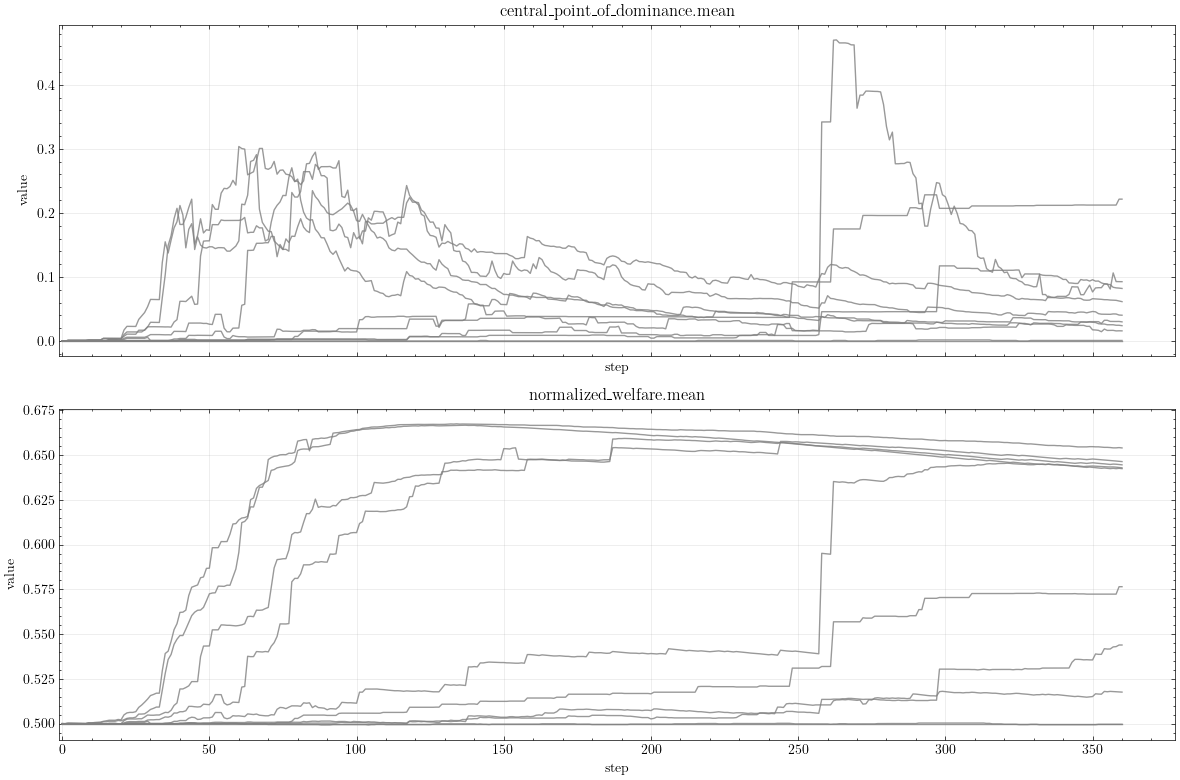

In [6]:
all_sample_labels = np.asarray(output_group["labels"].get("sample", np.arange(n_total)))
sample_labels = all_sample_labels[idx]  # same rows as timeseries_sample

observable_labels = tuple(output_group["labels"]["observable"])
step_labels = np.asarray(output_group["labels"]["step"])

n_plots = len(observable_labels)
fig, axes = plt.subplots(n_plots, 1, figsize=(12, 4 * n_plots), sharex=True)
axes = np.atleast_1d(axes)

for axis, observable_index in zip(axes, range(n_plots), strict=True):
    observable_name = observable_labels[observable_index]
    for row_index, sample_label in enumerate(sample_labels):
        axis.plot(
            step_labels,
            timeseries_sample[row_index, observable_index],
            alpha=0.8,
            label=f"sample {int(sample_label)}",
            c="gray"
        )
    axis.set_title(observable_name)
    axis.set_xlabel("step")
    axis.set_ylabel("value")
    axis.grid(alpha=0.3)
    axis.set_xlim(-1)

plt.tight_layout()
plt.show()

## Final-step pair plots

This cell uses `outputs["tensors"]["final"]` for the metric values and colors the pair plots by one observable at a time.


In [7]:
parameters = input_group["tensors"].get("parameters")
final = output_group["tensors"]["final"]
parameter_labels = tuple(input_group["labels"].get("parameter", ()))
parameter_labels

('benefit_to_cost_ratio',
 'distance_discount',
 'bridge_value',
 'inertia_term',
 'tau',
 'visibility_distance')

## Welfare Reference Values

This computes the observer-level `star`, `empty`, and optimized `random` welfare reference values for the loaded parameter tuple.


In [8]:
benefit_to_cost_ratio = np.unique(parameters[:, parameter_labels.index("benefit_to_cost_ratio")]).item()
distance_discount = np.unique(parameters[:, parameter_labels.index("distance_discount")]).item()

reference_welfare = NormalizedWelfareObserver.reference_values(
    n=metadata["simulation"]["n_agents"],
    benefit_to_cost_ratio=float(benefit_to_cost_ratio),
    distance_discount=float(distance_discount),
)

reference_welfare

{'star': 0.6914464542148091, 'empty': 0.5, 'random': 0.6420889763691808}

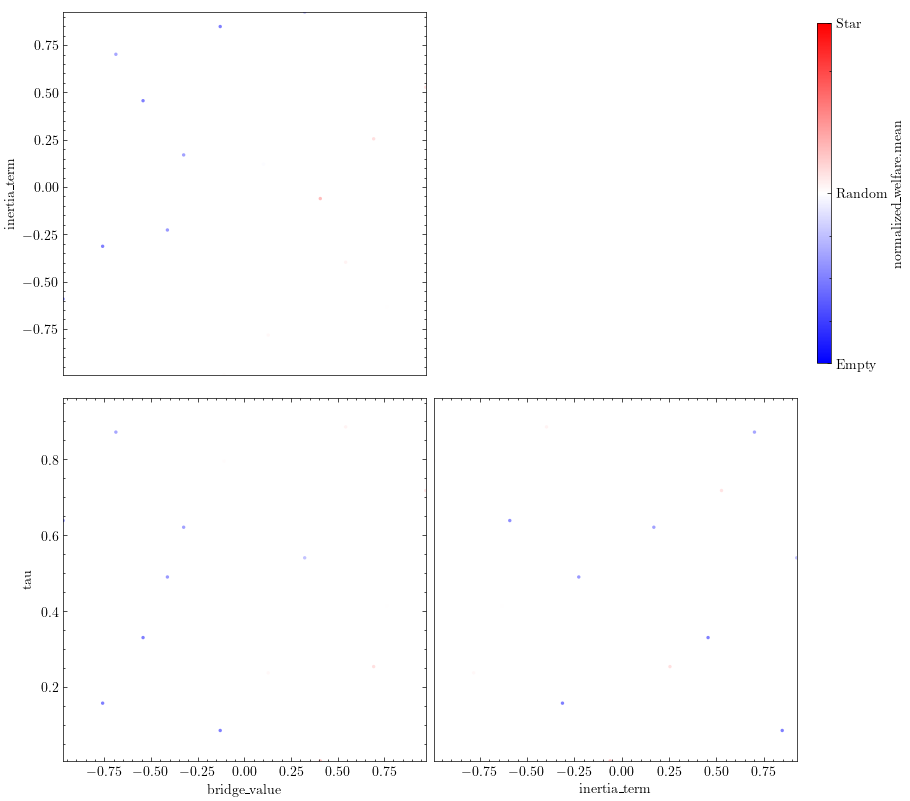

In [10]:
target_idx = 1
target_values = final[:, target_idx]
reference_center = float(reference_welfare["random"])
eps = np.finfo(float).eps
target_norm = TwoSlopeNorm(
    vmin=reference_welfare["empty"],
    vcenter=reference_center,
    vmax=reference_welfare["star"],
)

fig, axes = plot_pair(
    X=parameters,
    y=target_values,
    labels=parameter_labels,
    label_y=observable_labels[target_idx],
    atol=1e-5,
    base_fig_size=4.0,
    cmap="bwr",
    method="points",
    resolution=50,
    sigma=0.2,
    norm=target_norm,
)

cbar_ax = fig.axes[-1]
cbar_ax.set_yticks(
    [
        reference_welfare["empty"],
        reference_welfare["random"],
        reference_welfare["star"],
    ],
    labels=["Empty", "Random", "Star"],
);

In [11]:
dict(zip(parameter_labels, parameters[final[:, 0].argmax()]))

{'benefit_to_cost_ratio': np.float32(0.5),
 'distance_discount': np.float32(0.9),
 'bridge_value': np.float32(0.32397175),
 'inertia_term': np.float32(0.9241283),
 'tau': np.float32(0.54073477),
 'visibility_distance': np.float32(3.0)}

## Failure rows

If the task recorded failures, this cell shows the raw arrays stored under the `failures/` group.


In [13]:
failure_arrays if failure_arrays else "No stored failures."


{'error': array([], dtype='<U4096')}